In [1]:
!pip install -q shap lime

In [7]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully!")


All libraries imported successfully!


In [12]:

# Find your Kaggle input file
files = glob.glob(
    "/kaggle/input/datasets/kabure/german-credit-data-with-risk/german_credit_data.csv",
    recursive=True
)

file_path = files[0]

df = pd.read_csv(file_path)

# Remove unnecessary index column if present
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("Dataset loaded successfully!")
print("File:", file_path)
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
File: /kaggle/input/datasets/kabure/german-credit-data-with-risk/german_credit_data.csv
Shape: (1000, 10)

Column names:
['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

First five rows:


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB


In [14]:

# Automatically identify target column
target_candidates = [
    "Risk", "risk", "class", "creditability"
]

target_col = next(
    (c for c in df.columns if c.lower() in
     [x.lower() for x in target_candidates]),
    None
)

if target_col is None:
    raise ValueError(
        "Target column not found. Check your CSV columns."
    )

# Separate input and output
X = df.drop(columns=[target_col]).copy()
y_raw = df[target_col].copy()

# Convert target: Good = 0, Bad = 1
y_text = y_raw.astype(str).str.strip().str.lower()

y = y_text.map({
    "good": 0,
    "bad": 1
})

if y.isna().any():
    raise ValueError(
        "Unexpected target values: " +
        str(y_raw.unique())
    )

y = y.astype(int)

print("Target variable:", target_col)
print("\nTarget distribution:")
print(y.value_counts().rename({
    0: "Good",
    1: "Bad"
}))

print("\nFeatures:")
print(X.columns.tolist())


Target variable: Risk

Target distribution:
Risk
Good    700
Bad     300
Name: count, dtype: int64

Features:
['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose']


In [15]:

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# Handle missing values
for col in categorical_cols:
    X[col] = X[col].fillna("Missing").astype(str)

for col in numerical_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X[col] = X[col].fillna(X[col].median())

# Encode categorical columns
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_encoded = X.copy()

if categorical_cols:
    X_encoded[categorical_cols] = encoder.fit_transform(
        X[categorical_cols]
    )

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

print("\nEncoded dataset:")
display(X_encoded.head())

print("\nFinal dataset shape:", X_encoded.shape)


Categorical columns: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Numerical columns: ['Age', 'Job', 'Credit amount', 'Duration']

Encoded dataset:


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,1.0,2,1.0,0.0,1.0,1169,6,5.0
1,22,0.0,2,1.0,1.0,2.0,5951,48,5.0
2,49,1.0,1,1.0,1.0,0.0,2096,12,3.0
3,45,1.0,2,0.0,1.0,1.0,7882,42,4.0
4,53,1.0,2,0.0,1.0,1.0,4870,24,1.0



Final dataset shape: (1000, 9)


In [16]:

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training records: 800
Testing records: 200

Training distribution:
Risk
0    560
1    240
Name: count, dtype: int64

Testing distribution:
Risk
0    140
1     60
Name: count, dtype: int64


In [17]:

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [18]:

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")
print("------------------------------")
print("Model: Random Forest")
print("Trees: 200")
print("Maximum depth: 8")
print(f"Accuracy: {accuracy:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")


MODEL PERFORMANCE
------------------------------
Model: Random Forest
Trees: 200
Maximum depth: 8
Accuracy: 0.8000
ROC-AUC: 0.7989


In [19]:

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

# Extract SHAP values for Bad class (class 1)
if isinstance(shap_values, list):
    bad_shap = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    bad_shap = shap_values[:, :, 1]

else:
    bad_shap = shap_values

# Global importance
mean_shap = np.abs(bad_shap).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP": mean_shap
}).sort_values(
    "Mean_SHAP",
    ascending=False
).reset_index(drop=True)

print("GLOBAL SHAP FEATURE IMPORTANCE")
display(importance_df.head(5))

top_5_features = importance_df.head(5)["Feature"].tolist()

print("\nTOP 5 FEATURES:")
for rank, feature in enumerate(top_5_features, 1):
    print(rank, feature)


GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_SHAP
0,Checking account,0.110135
1,Duration,0.063388
2,Credit amount,0.045401
3,Saving accounts,0.032632
4,Age,0.022152



TOP 5 FEATURES:
1 Checking account
2 Duration
3 Credit amount
4 Saving accounts
5 Age


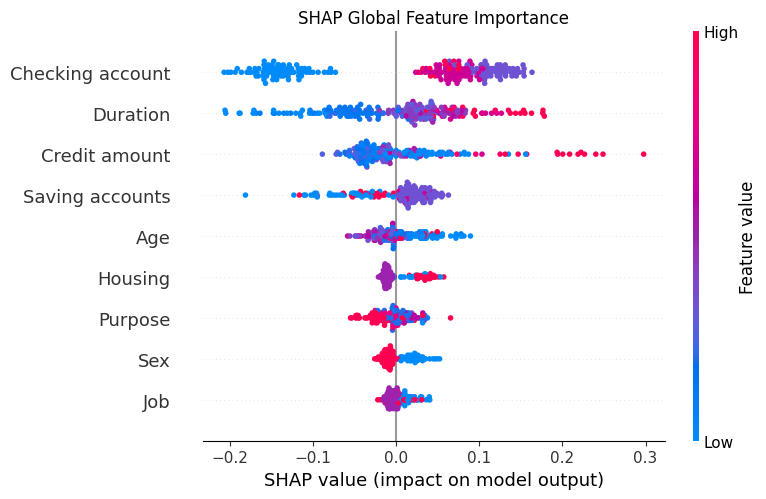

SHAP summary saved successfully!


In [20]:

plt.figure(figsize=(10, 6))

shap.summary_plot(
    bad_shap,
    X_test,
    show=False,
    max_display=20
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()

plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary saved successfully!")


In [21]:

# Find applicants predicted as Bad
rejected_positions = np.where(y_pred == 1)[0]

if len(rejected_positions) == 0:
    raise ValueError(
        "No rejected applicant found. "
        "Cannot perform local explanation."
    )

# Select first rejected applicant
applicant_position = rejected_positions[0]

applicant = X_test.iloc[applicant_position]

bad_probability = y_prob[applicant_position]

print("SELECTED APPLICANT")
print("------------------------------")
print("Test index:", applicant.name)
print(f"Probability of Bad: {bad_probability:.4f}")
print("Prediction: REJECTED")
print("Actual class:",
      "Bad" if y_test.iloc[applicant_position] == 1
      else "Good")


SELECTED APPLICANT
------------------------------
Test index: 289
Probability of Bad: 0.5438
Prediction: REJECTED
Actual class: Bad


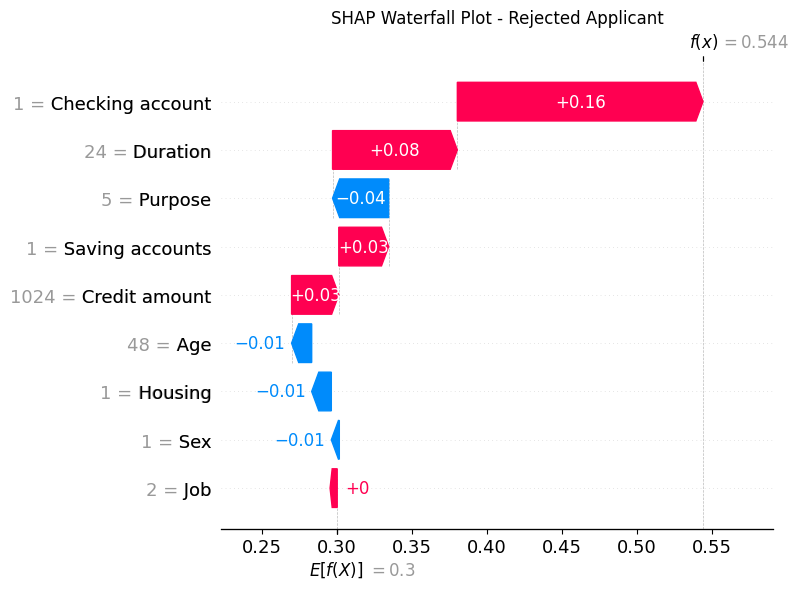


TOP 3 SHAP REJECTION REASONS
Checking account = 1.0 | SHAP = 0.1635
Duration = 24.0 | SHAP = 0.0831
Saving accounts = 1.0 | SHAP = 0.0332


In [22]:

# Get local SHAP values
local_shap = bad_shap[applicant_position]

# Get base value for Bad class
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    base_value = np.asarray(expected_value).flatten()[1]
else:
    base_value = expected_value

# Create SHAP explanation
local_explanation = shap.Explanation(
    values=local_shap,
    base_values=base_value,
    data=applicant.values,
    feature_names=X_test.columns.tolist()
)

# Waterfall plot
plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=False
)

plt.title("SHAP Waterfall Plot - Rejected Applicant")
plt.tight_layout()

plt.savefig(
    "shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Top 3 positive SHAP reasons
positive_indices = np.where(local_shap > 0)[0]

positive_indices = sorted(
    positive_indices,
    key=lambda i: local_shap[i],
    reverse=True
)

top_3_shap_indices = positive_indices[:3]

shap_top_names = [
    X_test.columns[i] for i in top_3_shap_indices
]

print("\nTOP 3 SHAP REJECTION REASONS")

for i in top_3_shap_indices:
    print(
        X_test.columns[i],
        "=",
        applicant.iloc[i],
        "| SHAP =",
        round(local_shap[i], 4)
    )


LIME EXPLANATION
------------------------------
Checking account=little : 0.1619
18.00 < Duration <= 24.00 : 0.0545
Saving accounts=little : 0.0528
Housing=own : -0.0463
Credit amount <= 1353.00 : 0.04


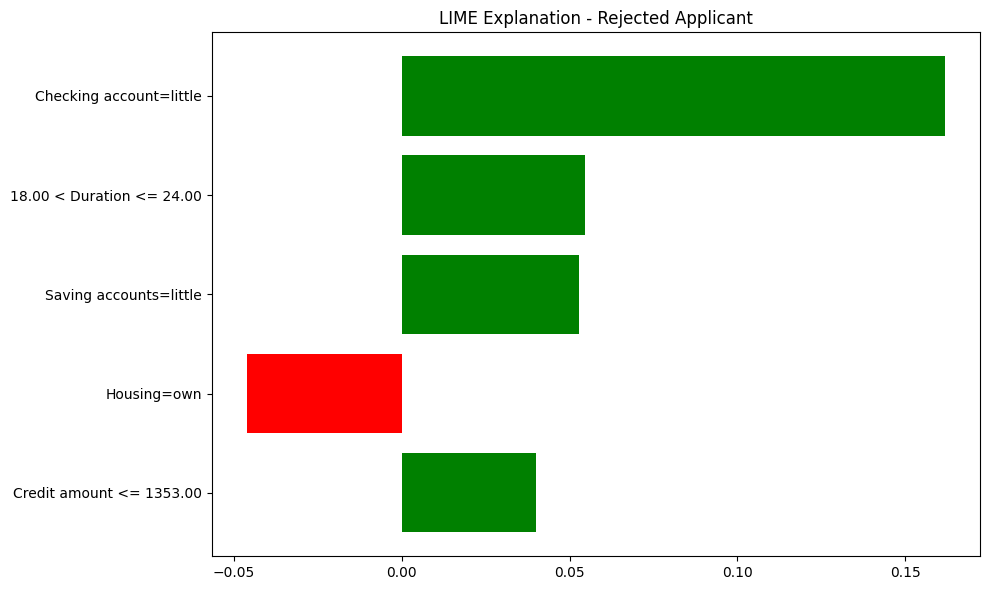

In [23]:

# Identify categorical column positions
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_cols
]

# Create categorical names for LIME
categorical_names = {}

for col in categorical_cols:
    idx = X_train.columns.get_loc(col)

    categories = encoder.categories_[
        categorical_cols.index(col)
    ]

    categorical_names[idx] = {
        i: str(value)
        for i, value in enumerate(categories)
    }

# Initialize LIME
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Good", "Bad"],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain the same rejected applicant
lime_exp = lime_explainer.explain_instance(
    data_row=applicant.values,
    predict_fn=model.predict_proba,
    num_features=5,
    labels=(1,)
)

print("LIME EXPLANATION")
print("------------------------------")

lime_reasons = lime_exp.as_list(label=1)

for feature, contribution in lime_reasons:
    print(feature, ":", round(contribution, 4))

# Save LIME plot
fig = lime_exp.as_pyplot_figure(label=1)

fig.set_size_inches(10, 6)
plt.title("LIME Explanation - Rejected Applicant")
plt.tight_layout()

plt.savefig(
    "lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [24]:

# Match LIME conditions to original feature names
def get_feature_name(condition, feature_names):
    for feature in sorted(
        feature_names,
        key=len,
        reverse=True
    ):
        if condition == feature or condition.startswith(feature + " "):
            return feature

    return None

# Select the three strongest positive LIME reasons
lime_positive = [
    (condition, weight)
    for condition, weight in lime_reasons
    if weight > 0
]

lime_positive.sort(
    key=lambda x: x[1],
    reverse=True
)

lime_top_names = []

for condition, weight in lime_positive:
    feature = get_feature_name(
        condition,
        X_test.columns.tolist()
    )

    if feature and feature not in lime_top_names:
        lime_top_names.append(feature)

    if len(lime_top_names) == 3:
        break

# Compare top three
agreement = len(
    set(shap_top_names) & set(lime_top_names)
)

print("SHAP TOP 3:")
print(shap_top_names)

print("\nLIME TOP 3 POSITIVE REASONS:")
print(lime_top_names)

print("\nTOP 3 AGREEMENT:", agreement, "/ 3")

print("\nCOMMON FEATURES:")
print(set(shap_top_names) & set(lime_top_names))


SHAP TOP 3:
['Checking account', 'Duration', 'Saving accounts']

LIME TOP 3 POSITIVE REASONS:
['Credit amount']

TOP 3 AGREEMENT: 0 / 3

COMMON FEATURES:
set()


In [25]:

sensitive_attributes = [
    "age",
    "personal_status",
    "foreign_worker",
    "sex"
]

# Case-insensitive matching
def is_sensitive(feature):
    return feature.lower().replace(" ", "_") in sensitive_attributes

shap_sensitive = [
    f for f in shap_top_names if is_sensitive(f)
]

lime_sensitive = [
    f for f in lime_top_names if is_sensitive(f)
]

print("SENSITIVE ATTRIBUTE AUDIT")
print("------------------------------")

print("SHAP:", shap_sensitive)
print("LIME:", lime_sensitive)

if shap_sensitive or lime_sensitive:
    print("\nWARNING: Sensitive attributes found.")
    print("Fairness review is required.")
else:
    print("\nNo sensitive attributes found in top 3 explanations.")


SENSITIVE ATTRIBUTE AUDIT
------------------------------
SHAP: []
LIME: []

No sensitive attributes found in top 3 explanations.


In [26]:

legitimate_reasons = []

for i in top_3_shap_indices:

    feature = X_test.columns[i]

    if is_sensitive(feature):
        continue

    value = applicant.iloc[i]

    # Convert encoded categorical values back to labels
    if feature in categorical_cols:

        category_index = int(round(float(value)))

        categories = encoder.categories_[
            categorical_cols.index(feature)
        ]

        if 0 <= category_index < len(categories):
            value = categories[category_index]

    legitimate_reasons.append(
        (feature, value)
    )

if legitimate_reasons:

    reason_text = "; ".join(
        f"{feature} = {value}"
        for feature, value in legitimate_reasons
    )

    rejection_message = (
        "Your EMI request was not approved. "
        "The main financial factors influencing the "
        "model's assessment were: "
        + reason_text +
        ". Please contact our support team for "
        "further information or a review of your application."
    )

else:

    rejection_message = (
        "Your EMI request was not approved. "
        "Please contact our support team for "
        "a detailed review of your application."
    )

print("CUSTOMER REJECTION MESSAGE")
print("------------------------------")
print(rejection_message)


CUSTOMER REJECTION MESSAGE
------------------------------
Your EMI request was not approved. The main financial factors influencing the model's assessment were: Checking account = little; Duration = 24.0; Saving accounts = little. Please contact our support team for further information or a review of your application.


In [27]:

# Save global importance
importance_df.to_csv(
    "global_shap_importance.csv",
    index=False
)

# Prepare results
results = {
    "Model": "Random Forest",
    "Accuracy": accuracy,
    "ROC-AUC": roc_auc,
    "Trees": 200,
    "Maximum Depth": 8,
    "Applicant Index": applicant.name,
    "Bad Probability": bad_probability,
    "Prediction": "REJECTED",
    "SHAP Top 3": str(shap_top_names),
    "LIME Top 3": str(lime_top_names),
    "Agreement": f"{agreement}/3",
    "SHAP Sensitive Attributes": str(shap_sensitive),
    "LIME Sensitive Attributes": str(lime_sensitive),
    "Rejection Message": rejection_message
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Metric", "Value"]
)

results_df.to_csv(
    "practical_results.csv",
    index=False
)

display(results_df)

print("\nALL FILES SAVED SUCCESSFULLY!")

print("""
1. shap_summary.png
2. shap_waterfall.png
3. lime_explanation.png
4. global_shap_importance.csv
5. practical_results.csv
""")


,Metric,Value
0,Model,Random Forest
1,Accuracy,0.8
2,ROC-AUC,0.798929
3,Trees,200
4,Maximum Depth,8
5,Applicant Index,289
6,Bad Probability,0.543766
7,Prediction,REJECTED
8,SHAP Top 3,"['Checking account', 'Duration', 'Saving accou..."
9,LIME Top 3,['Credit amount']



ALL FILES SAVED SUCCESSFULLY!

1. shap_summary.png
2. shap_waterfall.png
3. lime_explanation.png
4. global_shap_importance.csv
5. practical_results.csv

